# Daya Bay
ОБР описывается следующей реакций: $ν̄_e + p → n + e⁺$.
 Позитрон, образовавшийся в реакции, почти мгновенно аннигилирует с ближайшим электроном (мгновенное событие), затем, спустя некоторое время (около 200 мс), нейтрон захватывается ядром гадолиния (запаздывающее событие). За счет этого можно определить направление ОБР как вектор разности координат запаздывающего и мгновенного события.

Данные о событиях ОБР содержат в себе следующие характеристики:
- time_prompt_s : время метки
- day : день проведения эксперимента
- n_det : количество набирающих данные детекторов в текущий момент времени
- energy_prompt_MeV : реконструированная энергия мгновенного сигнала, МэВ
- energy_delayed_MeV : реконструированная энергия запаздывающего сигнала, МэВ
- delta_t_us : задержка по времени между запаздывающим и мгновенным сигналами, мкс
- vertex_prompt_x_mm : координата x мгновенного события относительно центра детектора, мм
- vertex_prompt_y_mm : координата y мгновенного события относительно центра детектора, мм
- vertex_prompt_z_mm : координата z мгновенного события относительно центра детектора, мм
- vertex_delayed_x_mm : координата x запаздывающего события относительно центра детектора, мм
- vertex_delayed_y_mm : координата y запаздывающего события относительно центра детектора, мм
- vertex_delayed_z_mm : координата z запаздывающего события относительно центра детектора, мм

In [20]:
import pandas as pd
import numpy as np
from scipy import stats
from matplotlib import pyplot as plt

def angles(df):
    x = df['vertex_delayed_x_mm']-df['vertex_prompt_x_mm']
    y = df['vertex_delayed_y_mm']-df['vertex_prompt_y_mm']
    z = df['vertex_delayed_z_mm']-df['vertex_prompt_z_mm']
    t = df['delta_t_us']
    ang = pd.DataFrame()
    ang['x'], ang['y'], ang['z'], ang['t'] = x,y,z, t
    ang['r'] = (x**2+y**2+z**2)**0.5
    ang['v'] = ang['r']/t
    ang['a'] = round(np.degrees(np.arctan2(ang['y'], ang['x'])) % 360)
    ang['h'] = round(np.degrees(np.arctan2(ang['z'], (ang['x'] ** 2 + ang['y'] ** 2) ** 0.5)))
    return ang
def path(n):
    return f'C:\\Users\\1\\Desktop\\files\\dayabay_events_AD{n}.tsv'


Общее описание:

In [2]:
with open(path(11)) as f:
    df = pd.read_csv(f, sep='\t')
ang = angles(df)
ang.describe()

,x,y,z,t,r,v,a,h
count,794335.000000,794335.000000,794335.000000,794335.000000,794335.000000,794335.000000,794335.000000,794335.000000
mean,8.370329,-5.572973,3.430964,35.107605,367.991405,22.607468,182.140978,0.090671
std,280.497345,282.510006,298.906999,31.010548,335.456563,40.410934,105.614808,40.241420
min,-3972.140010,-4628.015380,-4498.289790,1.012000,3.372651,0.063854,0.000000,-90.000000
25%,-120.011017,-135.213509,-135.692489,13.487001,199.733270,5.746341,89.000000,-31.000000
50%,8.340090,-5.739870,-0.039920,25.763001,297.952584,11.736513,185.000000,0.000000
75%,136.641085,123.321550,137.454971,46.525002,436.462924,24.687015,275.000000,31.000000
max,5756.639039,3888.369990,4406.189820,199.987000,7558.019161,3461.071849,360.000000,90.000000


Примечательный факт:

In [3]:
hc = ang.groupby(['h']).agg({'h':'count'})
ac = ang.groupby(['a']).agg({'a':'count'})
df = pd.DataFrame({'hc':hc['h'], 'ac':ac['a']})
df.corr()

,hc,ac
hc,1.000000,0.316448
ac,0.316448,1.000000


In [4]:
df = pd.DataFrame({'h':ang['h'], 'a':ang['a']})
df.corr()

,h,a
h,1.00000,-0.00691
a,-0.00691,1.00000


Распределение по азимутам:

C:\Users\1\PycharmProjects\lpr_python_1sem\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 794335.
  res = hypotest_fun_out(*samples, **kwds)


ShapiroResult(statistic=np.float64(0.9502031885468761), pvalue=np.float64(2.033828448664097e-129))
KstestResult(statistic=np.float64(0.9913131471571127), pvalue=np.float64(0.0), statistic_location=np.float64(3.0), statistic_sign=np.int8(-1))


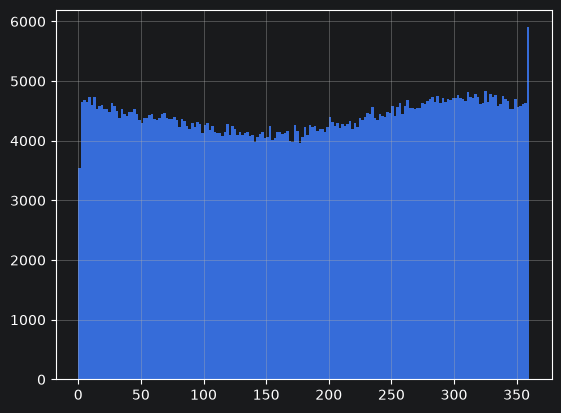

In [5]:
%matplotlib inline
p = ang['a'].hist(bins=180)
print(stats.shapiro(ang['a']))
print(stats.kstest(ang['a'], 'norm'))

Распределение по азимуту не гауссово по Шапиро и по Колмогорову-Смирнову с поправкой Лиллиефорса.

Распределение по высоте

ShapiroResult(statistic=np.float64(0.98360743132115), pvalue=np.float64(2.23620038118474e-98))
KstestResult(statistic=np.float64(0.47784716617931366), pvalue=np.float64(0.0), statistic_location=np.float64(3.0), statistic_sign=np.int8(-1))


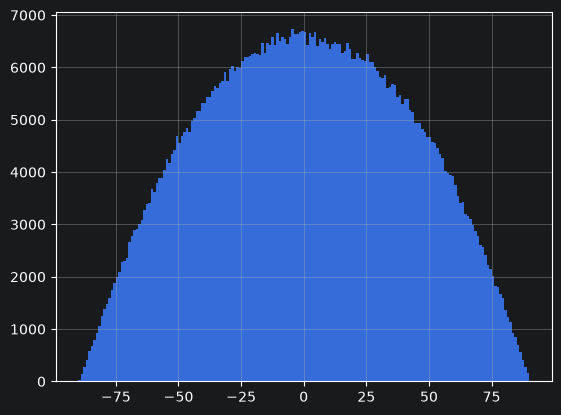

In [6]:
p = ang['h'].hist(bins=180)
print(stats.shapiro(ang['h']))
print(stats.kstest(ang['h'], 'norm'))

Распределение по высоте не гауссово по Шапиро и по Колмогорову-Смирнову с поправкой Лиллиефорса.

In [ ]:
a = ang['h']
# print(stats.vonmises.fit(a))
# print(stats.shapiro(a))
# print(stats.kstest(a, cdf='norm'))
# print(stats.kstest(a, cdf='vonmises', args=stats.vonmises.fit(a)))
print(stats.kstest(a, cdf='semicircular'))

In [9]:
def get_angles(n):
    with open(path(n)) as f:
        df = pd.read_csv(f, sep='\t')
        return angles(df)
a11, a12, a21, a22, a31, a32, a33, a34 = map(get_angles, [11,12,21,22,31,32,33,34])

# Распределение направлений по азимуту и высоте для 3 групп детекторов

## Группа 1 (AD11, AD12)

Корреляция азимутов

In [10]:
df = pd.DataFrame({'a11':a11['a'], 'a12':a12['a']})
df.corr()

,a11,a12
a11,1.000000,-0.000397
a12,-0.000397,1.000000


Корреляция высот

In [11]:
df = pd.DataFrame({'h11':a11['h'], 'h12':a12['h']})
df.corr()

,h11,h12
h11,1.000000,-0.000401
h12,-0.000401,1.000000


И для сравнения:

In [12]:
df = pd.DataFrame({'h11':a11['h'], 'a11':a11['a']})
df.corr()

,h11,a11
h11,1.00000,-0.00691
a11,-0.00691,1.00000


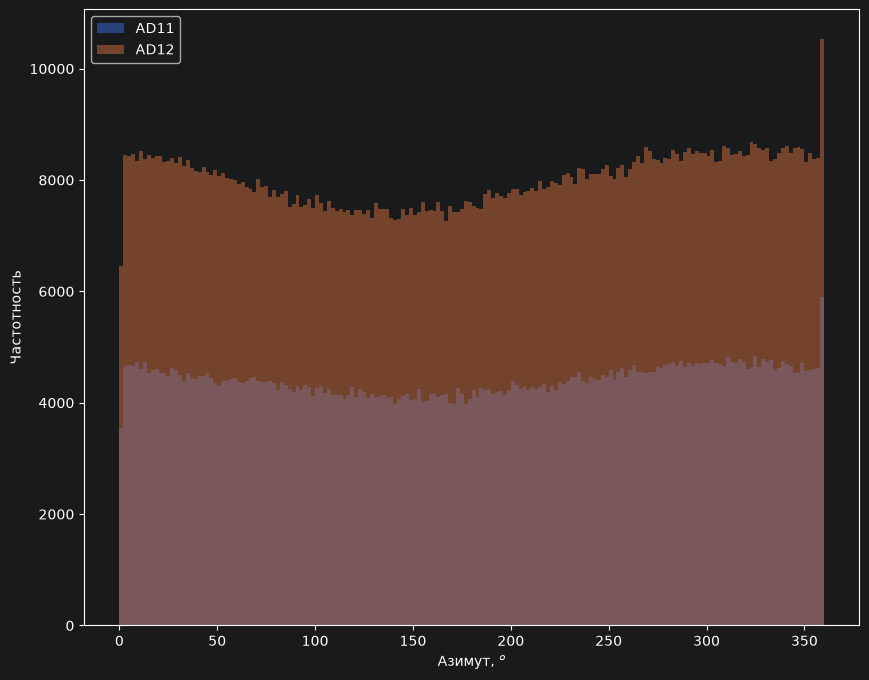

In [13]:
df = pd.DataFrame({'AD11':a11['a'], 'AD12':a12['a']})
plt = df.plot.hist(alpha=0.5, bins=180, subplots=False,
layout=(3, 1), figsize=(10, 8),xlabel=r'Азимут, $^o$', ylabel='Частотность')

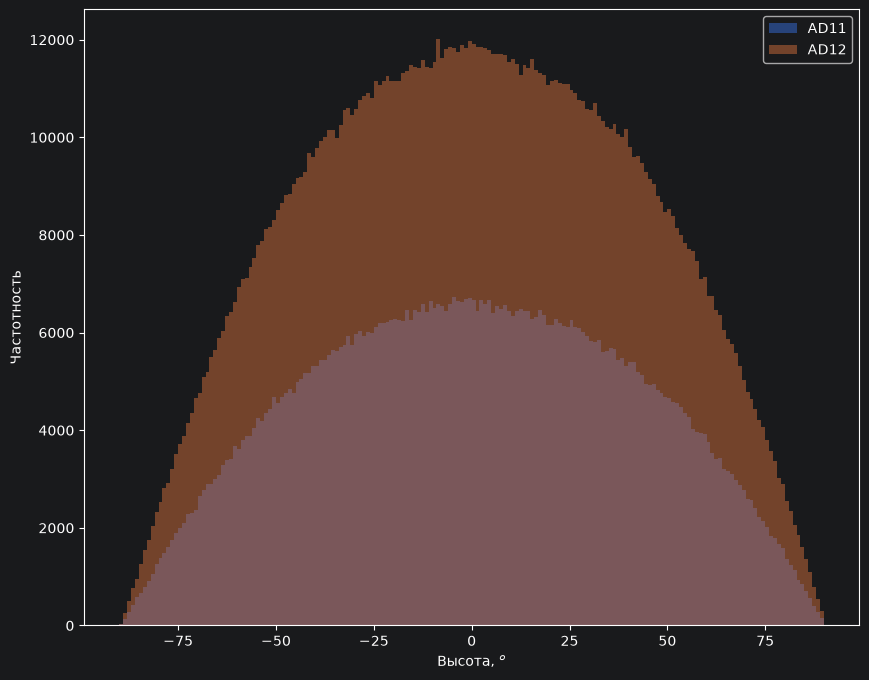

In [14]:
df = pd.DataFrame({'AD11':a11['h'], 'AD12':a12['h']})
plt = df.plot.hist(alpha=0.5, bins=180, subplots=False,
layout=(3, 1), figsize=(10, 8),xlabel=r'Высота, $^o$', ylabel='Частотность')

## Группа 2 (AD21, AD22)

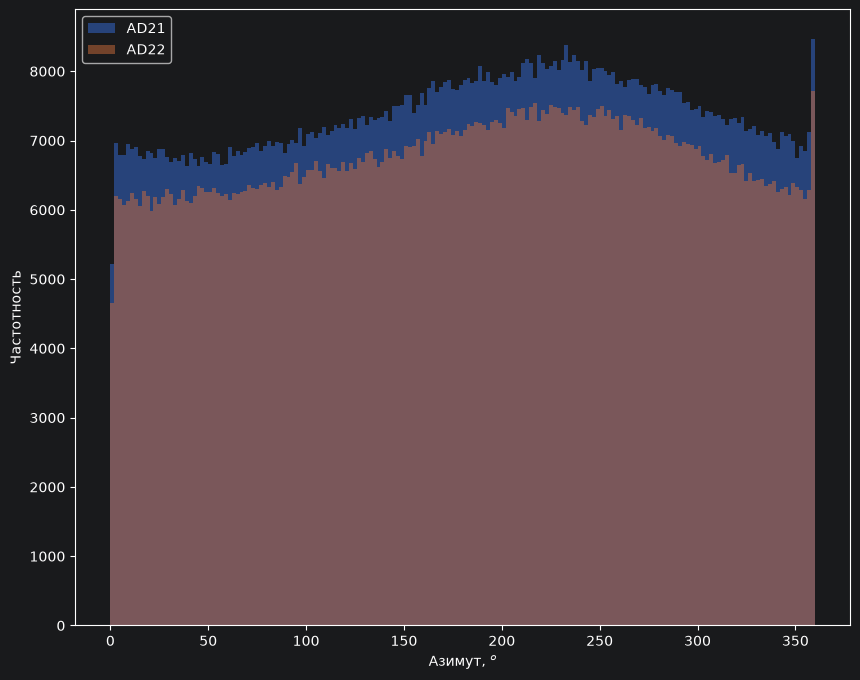

In [15]:
df = pd.DataFrame({'AD21':a21['a'], 'AD22':a22['a']})
plt = df.plot.hist(alpha=0.5, bins=180, subplots=False,
layout=(3, 1), figsize=(10, 8),xlabel=r'Азимут, $^o$', ylabel='Частотность')

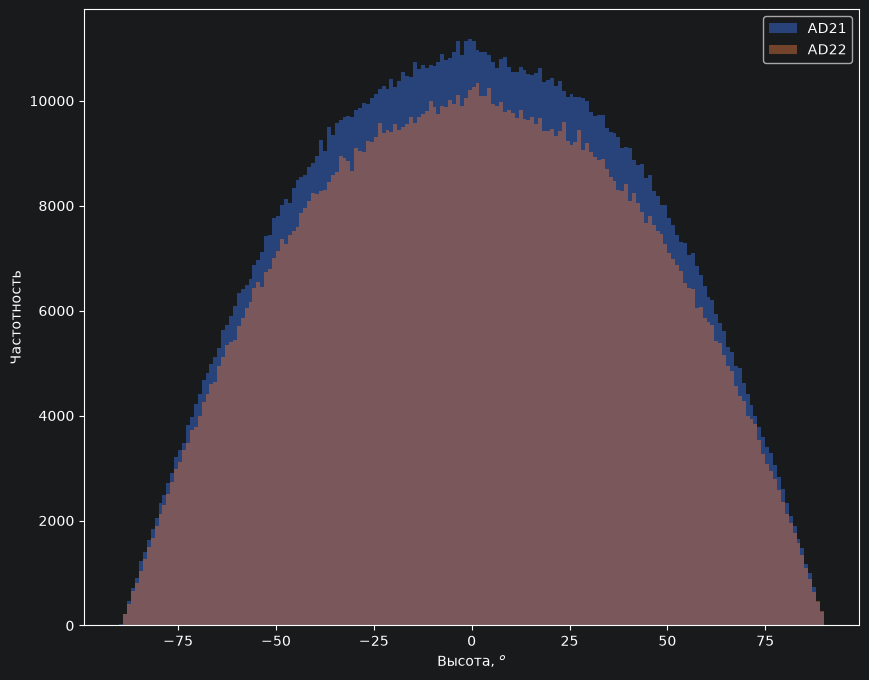

In [16]:
df = pd.DataFrame({'AD21':a21['h'], 'AD22':a22['h']})
plt = df.plot.hist(alpha=0.5, bins=180, subplots=False,
layout=(3, 1), figsize=(10, 8),xlabel=r'Высота, $^o$', ylabel='Частотность')

## Группа 3 (AD31, AD32, AD33, AD34)

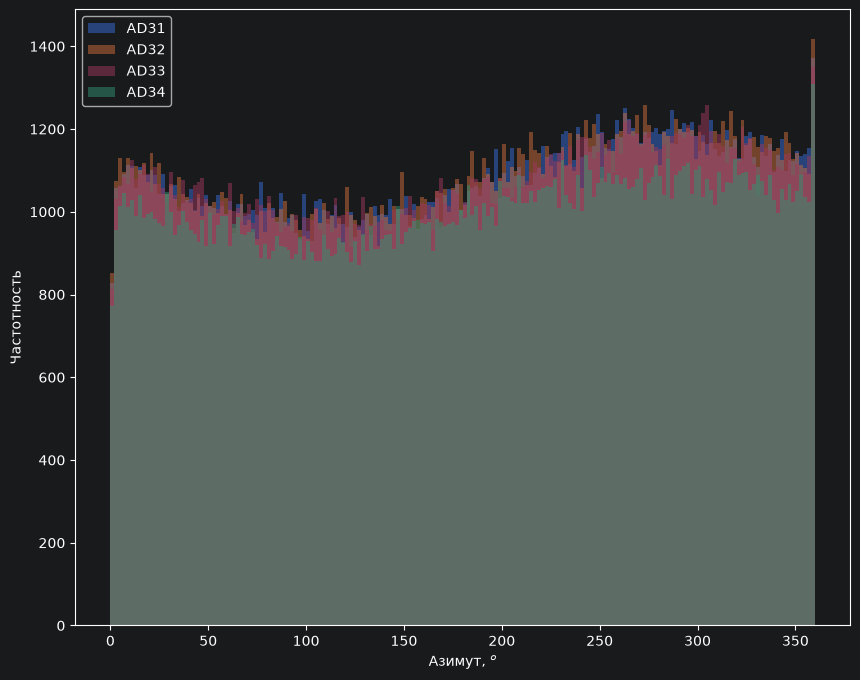

In [17]:
df = pd.DataFrame({'AD31':a31['a'], 'AD32':a32['a'],'AD33':a33['a'], 'AD34':a34['a'] })
plt = df.plot.hist(alpha=0.5, bins=180, subplots=False,
layout=(3, 1), figsize=(10, 8),xlabel=r'Азимут, $^o$', ylabel='Частотность')

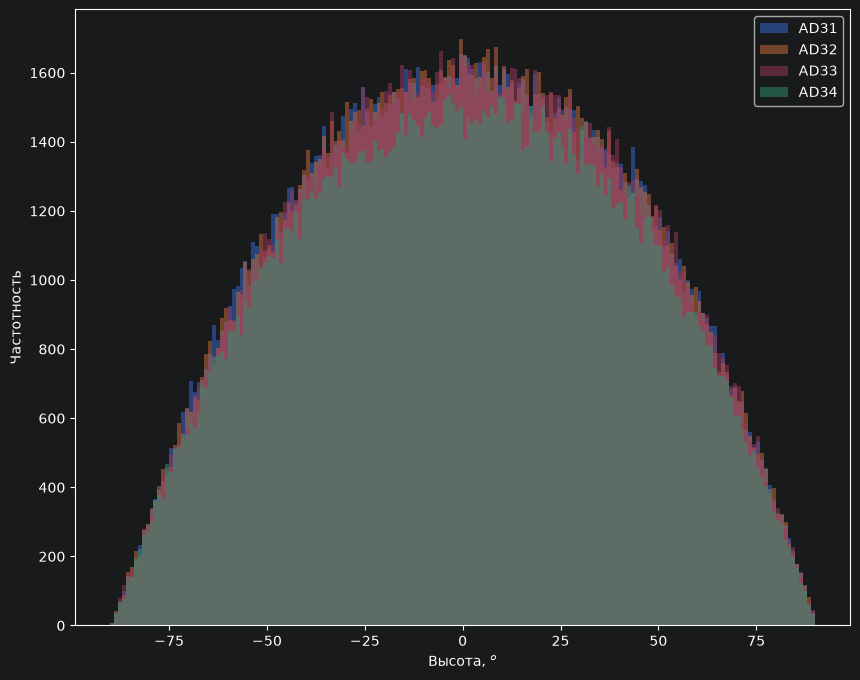

In [18]:
df = pd.DataFrame({'AD31':a31['h'], 'AD32':a32['h'],'AD33':a33['h'], 'AD34':a34['h'] })
plt = df.plot.hist(alpha=0.5, bins=180, subplots=False,
layout=(3, 1), figsize=(10, 8),xlabel=r'Высота, $^o$', ylabel='Частотность')

Видно сходство распределений внутри каждой группы, обусловленное геометрией установки. В рамках задачи можно считать ее "плоской": большая часть событий сосредоточена в плоскости реактора, высоты сгруппированы вблизи нуля.

# Геометрия

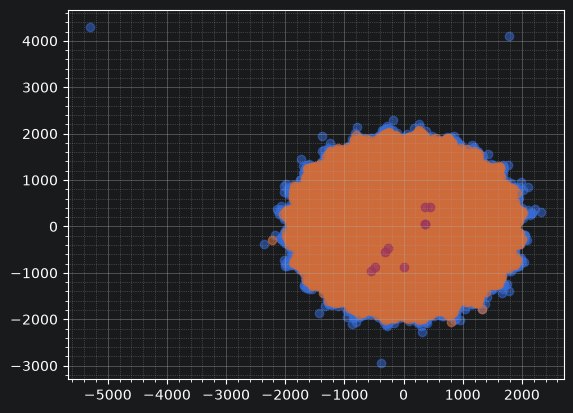

In [42]:
df = pd.read_csv(path(11), delimiter='\t')
plt.scatter(df['vertex_prompt_x_mm'], df['vertex_prompt_y_mm'], marker='o', alpha=0.5)
plt.scatter(df['vertex_delayed_x_mm'], df['vertex_delayed_y_mm'], marker='o', alpha=0.6)
a = angles(df)
df = pd.read_csv("coords.csv")
plt.scatter(df['X'], df['Y'], marker='o', alpha=0.75)
plt.minorticks_on()
plt.grid()
plt.grid(which="minor", linestyle=":")
plt.show()

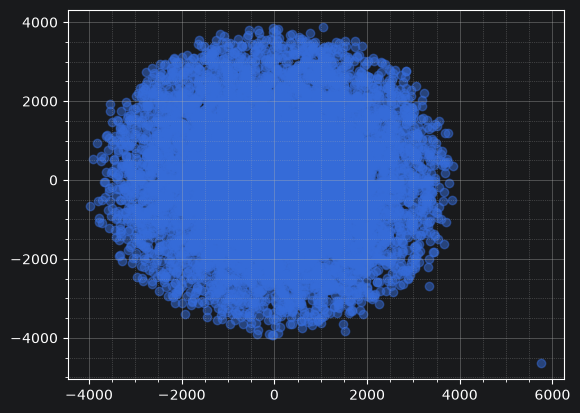

In [46]:
plt.scatter(a['x'], a['y'], marker='o', alpha=0.5)
plt.minorticks_on()
plt.grid()
plt.grid(which="minor", linestyle=":")
plt.show()